In [1]:
import pandas as pd
import numpy as np
import ast
from scipy.stats import ttest_ind, mannwhitneyu
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import chi2_contingency

In [2]:
data = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/everything_uk_genders.csv')

In [3]:
def calculate_stats(df):
    
    num_female_authors_list = []
    num_male_authors_list = []
    num_authors_list = []

    for _, row in df.iterrows():
        first_author_gender = row['first_author_gender']
        authors_genders_list = ast.literal_eval(row['authors_genders'])
        
        num_female_authors = authors_genders_list.count('female')
        if first_author_gender == 'female':
            num_female_authors += 1
        num_female_authors_list.append(num_female_authors)
        
        num_male_authors = authors_genders_list.count('male')
        if first_author_gender == 'male':
            num_male_authors += 1
        num_male_authors_list.append(num_male_authors)

        num_authors = len(authors_genders_list) + 1
        num_authors_list.append(num_authors)

    df['num_female_authors'] = num_female_authors_list
    df['num_male_authors'] = num_male_authors_list
    df['num_authors'] = num_authors_list

    df['ratio_female_authors'] = df['num_female_authors'] / df['num_authors']
    df['ratio_male_authors'] = df['num_male_authors'] / df['num_authors']
    
    return df

In [4]:
temp = calculate_stats(data)

print("Descriptive statistics for female ratio:")
print(temp['ratio_female_authors'].describe())
print("\nDescriptive statistics for male ratio:")
print(temp['ratio_male_authors'].describe())

Descriptive statistics for female ratio:
count    1922.000000
mean        0.283026
std         0.264144
min         0.000000
25%         0.000000
50%         0.250000
75%         0.500000
max         1.000000
Name: ratio_female_authors, dtype: float64

Descriptive statistics for male ratio:
count    1922.000000
mean        0.716974
std         0.264144
min         0.000000
25%         0.500000
50%         0.750000
75%         1.000000
max         1.000000
Name: ratio_male_authors, dtype: float64


In [5]:
title_first_author_ratios = temp.groupby('Publication Title')['first_author_gender'].value_counts(normalize=True).unstack()
title_first_author_ratios.fillna(0, inplace=True)

In [6]:
title_first_author_ratios

first_author_gender,female,male
Publication Title,,
Applied Catalysis A: General,0.359375,0.640625
International Journal of Greenhouse Gas Control,0.294915,0.705085
International Journal of Hydrogen Energy,0.270047,0.729953
Solar Energy,0.252525,0.747475
Transport in Porous Media,0.211864,0.788136


In [7]:
title_first_author_ratios = temp.groupby('Publication Title')['first_author_gender'].value_counts().unstack()
title_first_author_ratios.fillna(0, inplace=True)

chi2, p, dof, expected = chi2_contingency(title_first_author_ratios)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 12.627002305517063
P-value: 0.01324971760253973
Degrees of freedom: 4


In [8]:
title_first_author_ratios = temp.groupby('Publication Year')['first_author_gender'].value_counts().unstack()
title_first_author_ratios.fillna(0, inplace=True)

chi2, p, dof, expected = chi2_contingency(title_first_author_ratios)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 27.036908105730255
P-value: 0.012297095579919587
Degrees of freedom: 13


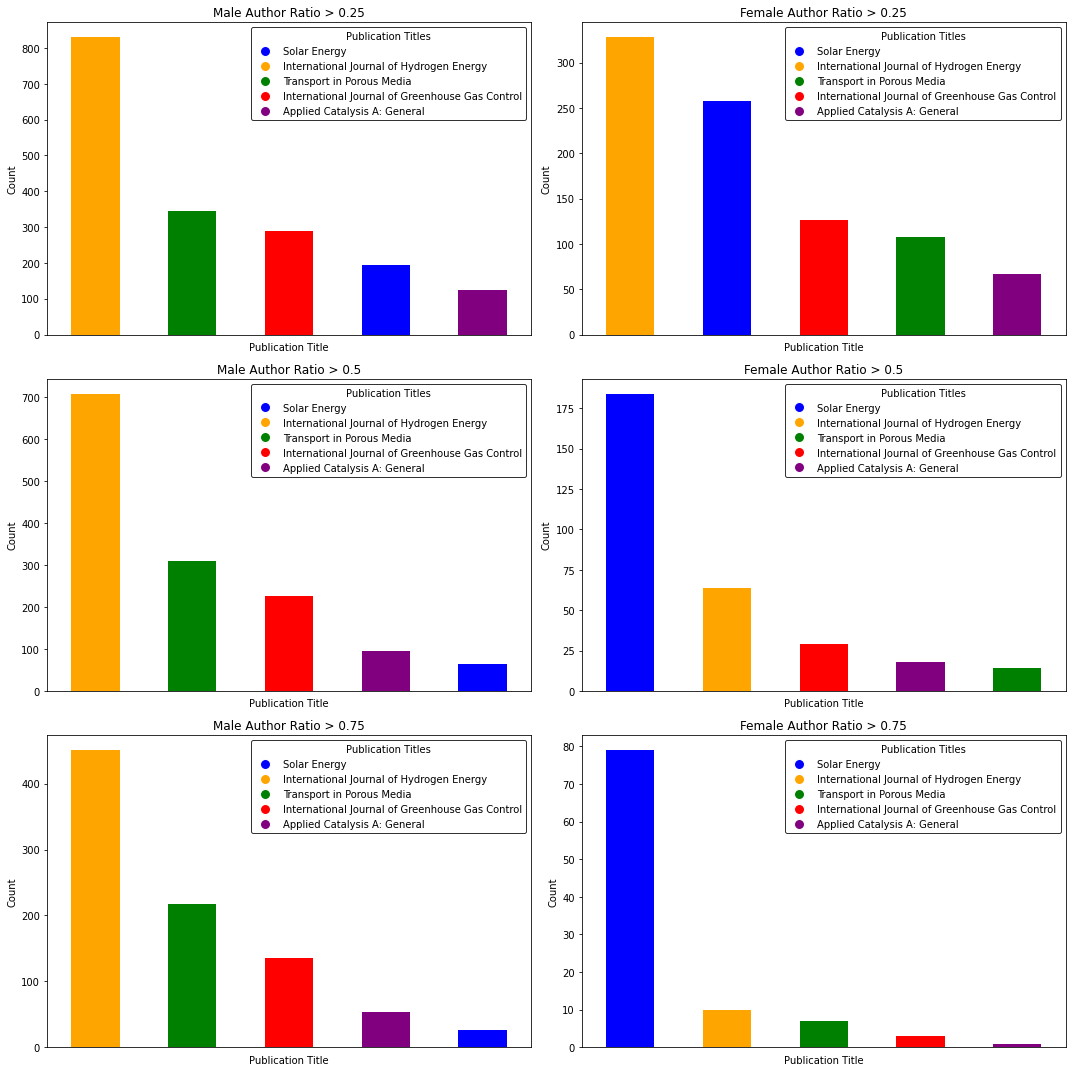

In [9]:
thresholds = [0.25, 0.5, 0.75]

fig = plt.figure(figsize=(15, 15))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.3)

title_colors = {
    "Solar Energy": 'blue',
    "International Journal of Hydrogen Energy": 'orange',
    "Transport in Porous Media": 'green',
    "International Journal of Greenhouse Gas Control": 'red',
    "Applied Catalysis A: General": 'purple'
}

for idx, threshold in enumerate(thresholds):
    subset_male = temp[temp['ratio_male_authors'] > threshold]
    title_counts_male = subset_male['Publication Title'].value_counts()
    
    ax_male = fig.add_subplot(gs[idx, 0])
    title_counts_male.plot(kind='bar', ax=ax_male, color=[title_colors.get(title, 'gray') for title in title_counts_male.index])
    
    ax_male.set_title(f"Male Author Ratio > {threshold}")
    ax_male.set_xlabel("Publication Title")
    ax_male.set_ylabel("Count")
    ax_male.set_xticks([])
    
    handles = [plt.Line2D([0], [0], marker='o', color='w', label=title, markersize=10, markerfacecolor=color) for title, color in title_colors.items()]
    legend = plt.legend(handles=handles, title="Publication Titles")
    legend.get_frame().set_edgecolor('black')
    
    subset_female = temp[temp['ratio_female_authors'] > threshold]
    title_counts_female = subset_female['Publication Title'].value_counts()
    
    ax_female = fig.add_subplot(gs[idx, 1])
    title_counts_female.plot(kind='bar', ax=ax_female, color=[title_colors.get(title, 'gray') for title in title_counts_female.index])
    
    ax_female.set_title(f"Female Author Ratio > {threshold}")
    ax_female.set_xlabel("Publication Title")
    ax_female.set_ylabel("Count")
    ax_female.set_xticks([])

    handles = [plt.Line2D([0], [0], marker='o', color='w', label=title, markersize=10, markerfacecolor=color) for title, color in title_colors.items()]
    legend = plt.legend(handles=handles, title="Publication Titles")
    legend.get_frame().set_edgecolor('black')

gs.tight_layout(fig)

plt.savefig('ratio-thresholds.png')

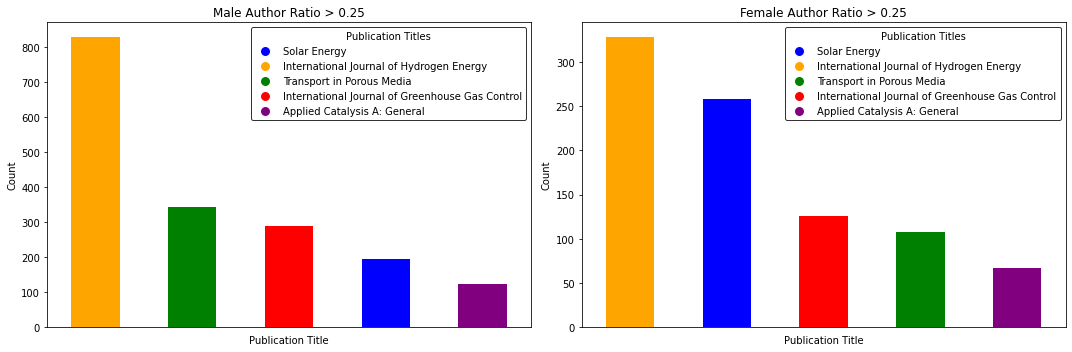

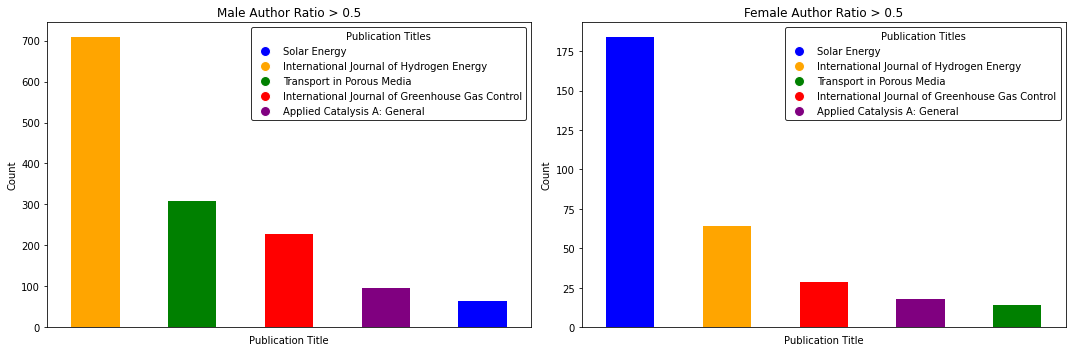

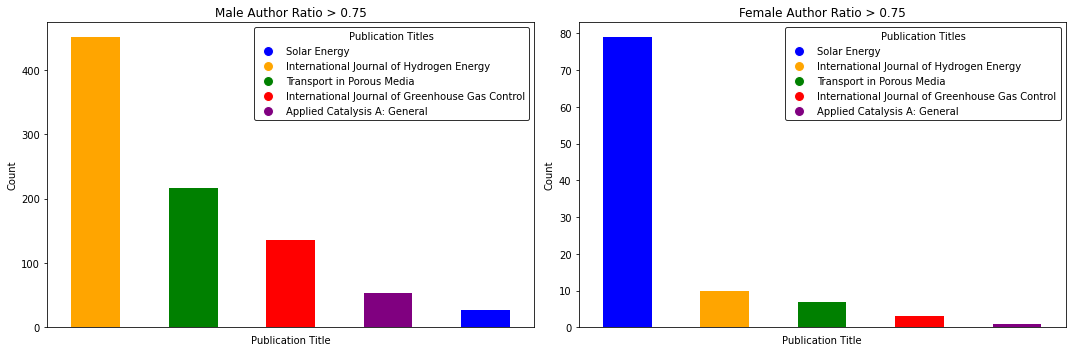

In [21]:
thresholds = [0.25, 0.5, 0.75]

title_colors = {
    "Solar Energy": 'blue',
    "International Journal of Hydrogen Energy": 'orange',
    "Transport in Porous Media": 'green',
    "International Journal of Greenhouse Gas Control": 'red',
    "Applied Catalysis A: General": 'purple'
}

for threshold in thresholds:
    fig, (ax_male, ax_female) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
    fig.subplots_adjust(wspace=0.3)

    subset_male = temp[temp['ratio_male_authors'] > threshold]
    title_counts_male = subset_male['Publication Title'].value_counts()
    
    title_counts_male.plot(kind='bar', ax=ax_male, color=[title_colors.get(title, 'gray') for title in title_counts_male.index])
    
    ax_male.set_title(f"Male Author Ratio > {threshold}")
    ax_male.set_xlabel("Publication Title")
    ax_male.set_ylabel("Count")
    ax_male.set_xticks([])

    handles = [plt.Line2D([0], [0], marker='o', color='w', label=title, markersize=10, markerfacecolor=color) for title, color in title_colors.items()]
    legend = ax_male.legend(handles=handles, title="Publication Titles", loc='upper right')
    legend.get_frame().set_edgecolor('black')

    subset_female = temp[temp['ratio_female_authors'] > threshold]
    title_counts_female = subset_female['Publication Title'].value_counts()
    
    title_counts_female.plot(kind='bar', ax=ax_female, color=[title_colors.get(title, 'gray') for title in title_counts_female.index])
    
    ax_female.set_title(f"Female Author Ratio > {threshold}")
    ax_female.set_xlabel("Publication Title")
    ax_female.set_ylabel("Count")
    ax_female.set_xticks([])

    handles = [plt.Line2D([0], [0], marker='o', color='w', label=title, markersize=10, markerfacecolor=color) for title, color in title_colors.items()]
    legend = ax_female.legend(handles=handles, title="Publication Titles", loc='upper right')
    legend.get_frame().set_edgecolor('black')

    plt.tight_layout()
    plt.savefig(f'ratio-threshold-{threshold}.png')
    plt.show()

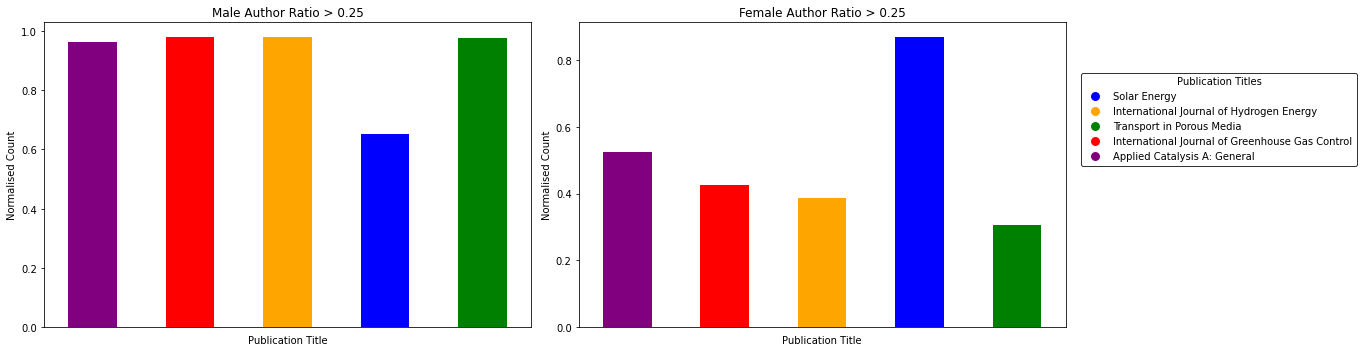

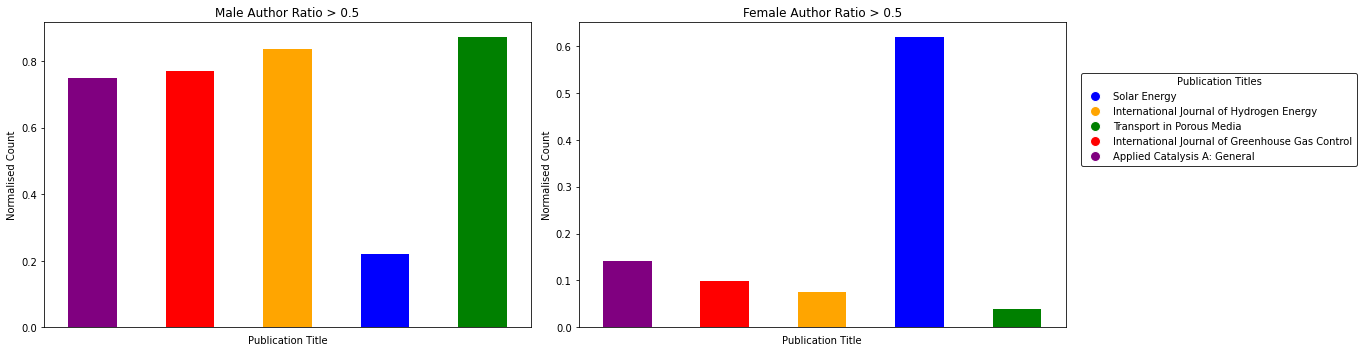

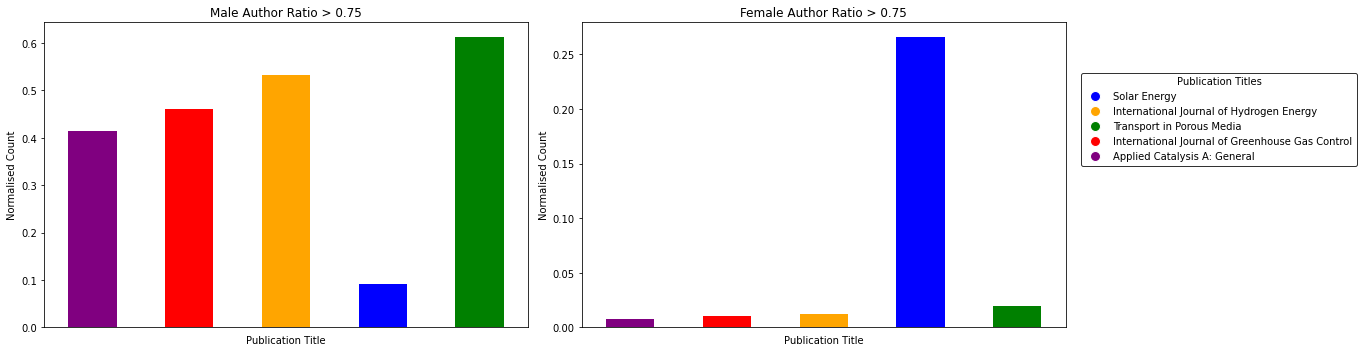

In [44]:
thresholds = [0.25, 0.5, 0.75]

title_colors = {
    "Solar Energy": 'blue',
    "International Journal of Hydrogen Energy": 'orange',
    "Transport in Porous Media": 'green',
    "International Journal of Greenhouse Gas Control": 'red',
    "Applied Catalysis A: General": 'purple'
}

total_counts = temp['Publication Title'].value_counts()

for threshold in thresholds:
    fig, (ax_male, ax_female) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
    fig.subplots_adjust(wspace=0.3, right=0.85)

    subset_male = temp[temp['ratio_male_authors'] > threshold]
    title_counts_male = subset_male['Publication Title'].value_counts() / total_counts
    
    title_counts_male.plot(kind='bar', ax=ax_male, color=[title_colors.get(title, 'gray') for title in title_counts_male.index])
    
    ax_male.set_title(f"Male Author Ratio > {threshold}")
    ax_male.set_xlabel("Publication Title")
    ax_male.set_ylabel("Normalised Count")
    ax_male.set_xticks([])

    subset_female = temp[temp['ratio_female_authors'] > threshold]
    title_counts_female = subset_female['Publication Title'].value_counts() / total_counts
    
    title_counts_female.plot(kind='bar', ax=ax_female, color=[title_colors.get(title, 'gray') for title in title_counts_female.index])
    
    ax_female.set_title(f"Female Author Ratio > {threshold}")
    ax_female.set_xlabel("Publication Title")
    ax_female.set_ylabel("Normalised Count")
    ax_female.set_xticks([])

    handles = [plt.Line2D([0], [0], marker='o', color='w', label=title, markersize=10, markerfacecolor=color) for title, color in title_colors.items()]
    legend = fig.legend(handles=handles, title="Publication Titles", loc='upper left', bbox_to_anchor=(1, 0.8))
    legend.get_frame().set_edgecolor('black')

    plt.tight_layout()
    plt.savefig(f'normalised-ratio-threshold-{threshold}.png', bbox_inches='tight')
    plt.show()

In [14]:
def calculate_for_title(publication_title, data):
    
    data = data[data['Publication Title'] == publication_title].copy()  # Making a copy to avoid warnings
    
    df = calculate_stats(data)

    female_auth_female = df[df['first_author_gender'] == 'female']['ratio_female_authors']
    male_auth_female = df[df['first_author_gender'] == 'male']['ratio_female_authors']
    
    female_auth_male = df[df['first_author_gender'] == 'female']['ratio_male_authors']
    male_auth_male = df[df['first_author_gender'] == 'male']['ratio_male_authors']
    
    print("Female First Author (Female) - Descriptive Statistics:")
    print(female_auth_female.describe())
    print("\nMale First Author (Female) - Descriptive Statistics:")
    print(male_auth_female.describe())
    print("Female First Author (Male) - Descriptive Statistics:")
    print(female_auth_male.describe())
    print("\nMale First Author (Male) - Descriptive Statistics:")
    print(male_auth_male.describe())
    
    plt.hist(male_auth_female, alpha=0.5, label='Male First Author')
    plt.hist(female_auth_female, alpha=0.5, label='Female First Author')
    plt.legend(loc='upper right')
    plt.xlabel("Ratio of Female Authors")
    plt.ylabel("Frequency")
    plt.title("Distribution of Female Author Ratios")
    plt.show()
    
    print("\nT-test for Difference in Means:")
    print(ttest_ind(female_auth_female, male_auth_female))

    print("\nMann-Whitney U Test:")
    print(mannwhitneyu(female_auth_female, male_auth_female))

    print("\nLevene's Test for Equal Variances:")
    print(stats.levene(female_auth_female, male_auth_female))

Female First Author (Female) - Descriptive Statistics:
count    75.000000
mean      0.820698
std       0.165531
min       0.500000
25%       0.666667
50%       0.833333
75%       1.000000
max       1.000000
Name: ratio_female_authors, dtype: float64

Male First Author (Female) - Descriptive Statistics:
count    222.000000
mean       0.525499
std        0.246416
min        0.000000
25%        0.333333
50%        0.585714
75%        0.714286
max        0.900000
Name: ratio_female_authors, dtype: float64
Female First Author (Male) - Descriptive Statistics:
count    75.000000
mean      0.179302
std       0.165531
min       0.000000
25%       0.000000
50%       0.166667
75%       0.333333
max       0.500000
Name: ratio_male_authors, dtype: float64

Male First Author (Male) - Descriptive Statistics:
count    222.000000
mean       0.474501
std        0.246416
min        0.100000
25%        0.285714
50%        0.414286
75%        0.666667
max        1.000000
Name: ratio_male_authors, dtype: fl

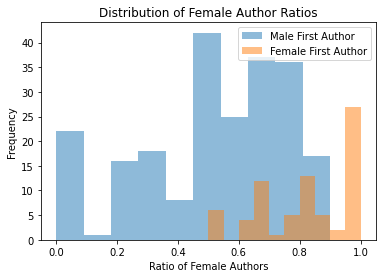


T-test for Difference in Means:
TtestResult(statistic=9.659050467511944, pvalue=2.3378210068843764e-19, df=295.0)

Mann-Whitney U Test:
MannwhitneyuResult(statistic=13938.5, pvalue=1.809508734031671e-18)

Levene's Test for Equal Variances:
LeveneResult(statistic=8.327100185700813, pvalue=0.004193970150688077)


In [15]:
calculate_for_title('Solar Energy', data)

Female First Author (Female) - Descriptive Statistics:
count    229.000000
mean       0.419356
std        0.185353
min        0.125000
25%        0.285714
50%        0.400000
75%        0.500000
max        1.000000
Name: ratio_female_authors, dtype: float64

Male First Author (Female) - Descriptive Statistics:
count    619.000000
mean       0.152021
std        0.177607
min        0.000000
25%        0.000000
50%        0.111111
75%        0.250000
max        0.750000
Name: ratio_female_authors, dtype: float64
Female First Author (Male) - Descriptive Statistics:
count    229.000000
mean       0.580644
std        0.185353
min        0.000000
25%        0.500000
50%        0.600000
75%        0.714286
max        0.875000
Name: ratio_male_authors, dtype: float64

Male First Author (Male) - Descriptive Statistics:
count    619.000000
mean       0.847979
std        0.177607
min        0.250000
25%        0.750000
50%        0.888889
75%        1.000000
max        1.000000
Name: ratio_male_au

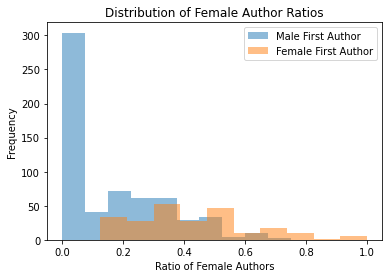


T-test for Difference in Means:
TtestResult(statistic=19.231214267930664, pvalue=1.1759509905076971e-68, df=846.0)

Mann-Whitney U Test:
MannwhitneyuResult(statistic=120108.5, pvalue=3.573333128431588e-57)

Levene's Test for Equal Variances:
LeveneResult(statistic=0.25212777461467123, pvalue=0.6157114742316339)


In [16]:
calculate_for_title('International Journal of Hydrogen Energy', data)

Female First Author (Female) - Descriptive Statistics:
count    87.000000
mean      0.416024
std       0.191617
min       0.100000
25%       0.250000
50%       0.400000
75%       0.500000
max       1.000000
Name: ratio_female_authors, dtype: float64

Male First Author (Female) - Descriptive Statistics:
count    208.000000
mean       0.200864
std        0.192743
min        0.000000
25%        0.000000
50%        0.166667
75%        0.333333
max        0.666667
Name: ratio_female_authors, dtype: float64
Female First Author (Male) - Descriptive Statistics:
count    87.000000
mean      0.583976
std       0.191617
min       0.000000
25%       0.500000
50%       0.600000
75%       0.750000
max       0.900000
Name: ratio_male_authors, dtype: float64

Male First Author (Male) - Descriptive Statistics:
count    208.000000
mean       0.799136
std        0.192743
min        0.333333
25%        0.666667
50%        0.833333
75%        1.000000
max        1.000000
Name: ratio_male_authors, dtype: fl

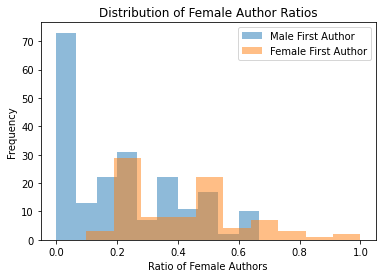


T-test for Difference in Means:
TtestResult(statistic=8.758059571659762, pvalue=1.620847766696522e-16, df=293.0)

Mann-Whitney U Test:
MannwhitneyuResult(statistic=14170.0, pvalue=9.582304325899741e-15)

Levene's Test for Equal Variances:
LeveneResult(statistic=0.024731723258515054, pvalue=0.8751457138260318)


In [17]:
calculate_for_title('International Journal of Greenhouse Gas Control', data)

Female First Author (Female) - Descriptive Statistics:
count    46.000000
mean      0.445534
std       0.184406
min       0.083333
25%       0.333333
50%       0.436508
75%       0.592857
max       0.833333
Name: ratio_female_authors, dtype: float64

Male First Author (Female) - Descriptive Statistics:
count    82.000000
mean      0.195193
std       0.190669
min       0.000000
25%       0.000000
50%       0.183333
75%       0.333333
max       0.750000
Name: ratio_female_authors, dtype: float64
Female First Author (Male) - Descriptive Statistics:
count    46.000000
mean      0.554466
std       0.184406
min       0.166667
25%       0.407143
50%       0.563492
75%       0.666667
max       0.916667
Name: ratio_male_authors, dtype: float64

Male First Author (Male) - Descriptive Statistics:
count    82.000000
mean      0.804807
std       0.190669
min       0.250000
25%       0.666667
50%       0.816667
75%       1.000000
max       1.000000
Name: ratio_male_authors, dtype: float64


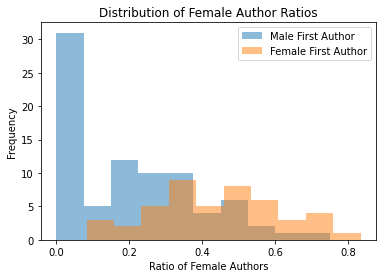


T-test for Difference in Means:
TtestResult(statistic=7.211088476708794, pvalue=4.540956475217338e-11, df=126.0)

Mann-Whitney U Test:
MannwhitneyuResult(statistic=3105.5, pvalue=9.94686196973711e-10)

Levene's Test for Equal Variances:
LeveneResult(statistic=0.16116517616508438, pvalue=0.6887660848891402)


In [18]:
calculate_for_title('Applied Catalysis A: General', data)

Female First Author (Female) - Descriptive Statistics:
count    75.000000
mean      0.425868
std       0.217042
min       0.142857
25%       0.333333
50%       0.333333
75%       0.500000
max       1.000000
Name: ratio_female_authors, dtype: float64

Male First Author (Female) - Descriptive Statistics:
count    279.000000
mean       0.104717
std        0.165824
min        0.000000
25%        0.000000
50%        0.000000
75%        0.200000
max        0.750000
Name: ratio_female_authors, dtype: float64
Female First Author (Male) - Descriptive Statistics:
count    75.000000
mean      0.574132
std       0.217042
min       0.000000
25%       0.500000
50%       0.666667
75%       0.666667
max       0.857143
Name: ratio_male_authors, dtype: float64

Male First Author (Male) - Descriptive Statistics:
count    279.000000
mean       0.895283
std        0.165824
min        0.250000
25%        0.800000
50%        1.000000
75%        1.000000
max        1.000000
Name: ratio_male_authors, dtype: fl

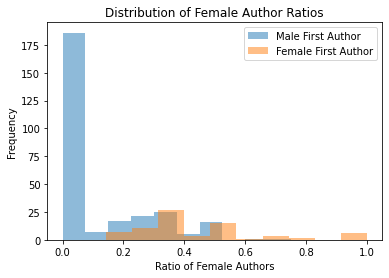


T-test for Difference in Means:
TtestResult(statistic=13.885385676764145, pvalue=2.91700972451434e-35, df=352.0)

Mann-Whitney U Test:
MannwhitneyuResult(statistic=18555.5, pvalue=7.18638015988135e-29)

Levene's Test for Equal Variances:
LeveneResult(statistic=3.2394410462160117, pvalue=0.07274132031500402)


In [19]:
calculate_for_title('Transport in Porous Media', data)

In [16]:
def plot_ratios_by_year(publication_title, data):
    
    data = data[data['Publication Title'] == publication_title].copy()
    
    df = calculate_stats(data)
    
    grouped = df.groupby('Publication Year')
    
    mean_ratios = {}
    sd_ratios = {}
    mean_ratios1 = {}
    sd_ratios1 = {}
    
    for year, group_df in grouped:
        female_authors_ratio = group_df['ratio_female_authors']
        male_authors_ratio = group_df['ratio_male_authors']
        
        mean_ratio = female_authors_ratio.mean()
        sd_ratio = female_authors_ratio.std()
        
        mean_ratio1 = male_authors_ratio.mean()
        sd_ratio1 = male_authors_ratio.std()
        
        mean_ratios[year] = mean_ratio
        sd_ratios[year] = sd_ratio
        
        mean_ratios1[year] = mean_ratio1
        sd_ratios1[year] = sd_ratio1
    
    mean_series = pd.Series(mean_ratios)
    sd_series = pd.Series(sd_ratios)
    
    mean_series1 = pd.Series(mean_ratios1)
    sd_series1 = pd.Series(sd_ratios1)
    
    return mean_series, sd_series, mean_series1, sd_series1

In [17]:
filtered_data = data[(data['Publication Year'] >= 2010) & (data['Publication Year'] <= 2023)]

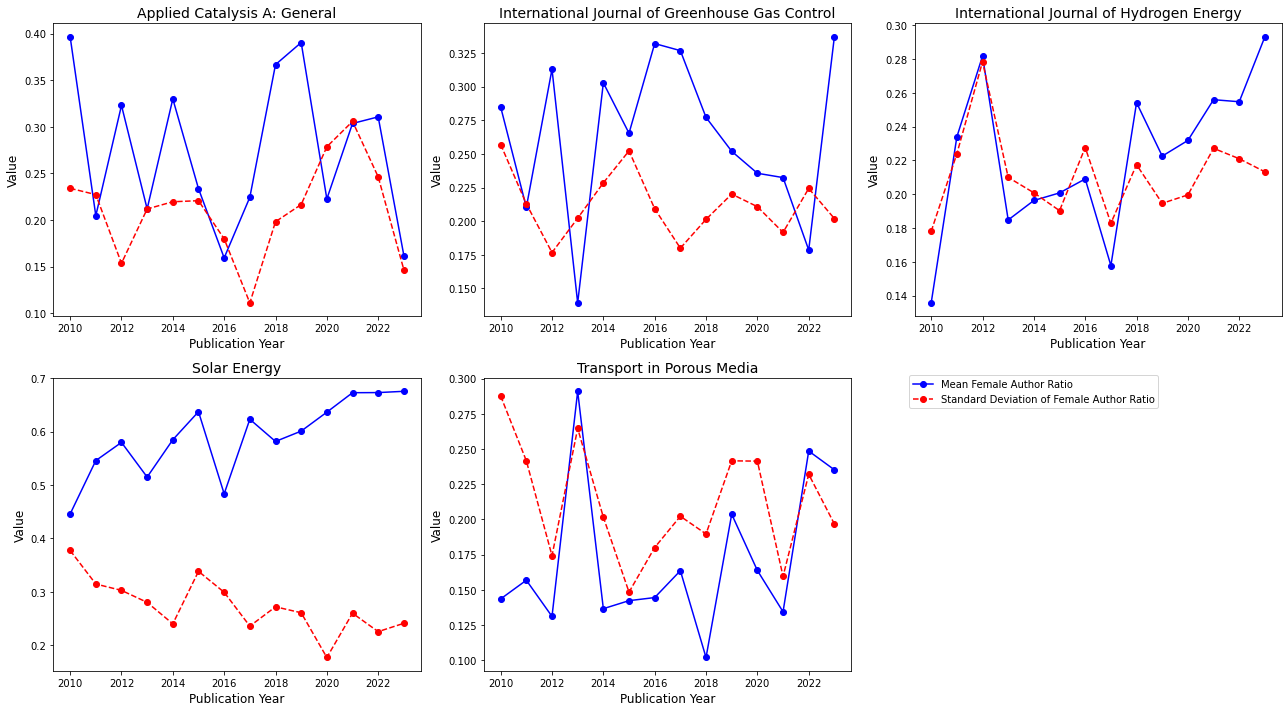

In [18]:
publication_titles = [
    'Applied Catalysis A: General',
    'International Journal of Greenhouse Gas Control',
    'International Journal of Hydrogen Energy',
    'Solar Energy',
    'Transport in Porous Media'
]

spec = gridspec.GridSpec(2, 3, figure=plt.figure(figsize=(18, 10)))

for i, title in enumerate(publication_titles):
    if i >= 5:
        break
    
    row = i // 3
    col = i % 3
    
    ax = plt.subplot(spec[row, col])
    
    mean_series, sd_series, mean_series1, sd_series1 = plot_ratios_by_year(title, filtered_data)
    
    mean_series.plot(ax=ax, marker='o', linestyle='-', color='b', label='Mean Female Author Ratio')
    sd_series.plot(ax=ax, marker='o', linestyle='--', color='r', label='Standard Deviation of Female Author Ratio')
    
    ax.set_title(f"{title}", fontsize = 14)
    ax.set_xlabel("Publication Year", fontsize = 12)
    ax.set_ylabel("Value", fontsize = 12)

handles, labels = ax.get_legend_handles_labels()
plt.figlegend(handles, labels, loc='upper left', ncol=1, bbox_to_anchor=(0.7, 0.48))

plt.tight_layout()
plt.savefig('mean_std_female_representation.png')

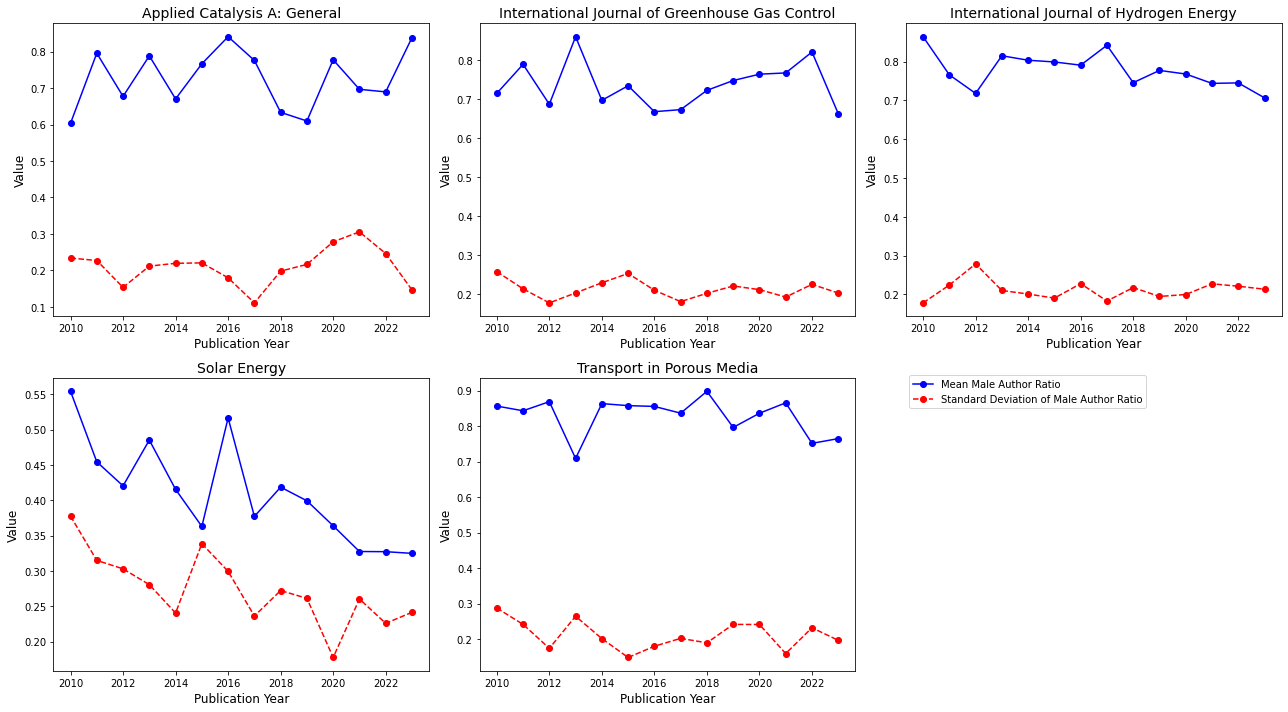

In [19]:
spec = gridspec.GridSpec(2, 3, figure=plt.figure(figsize=(18, 10)))

for i, title in enumerate(publication_titles):
    if i >= 5:
        break
    
    row = i // 3
    col = i % 3
    
    ax = plt.subplot(spec[row, col])
    
    mean_series, sd_series, mean_series1, sd_series1 = plot_ratios_by_year(title, filtered_data)
    
    mean_series1.plot(ax=ax, marker='o', linestyle='-', color='b', label='Mean Male Author Ratio')
    sd_series1.plot(ax=ax, marker='o', linestyle='--', color='r', label='Standard Deviation of Male Author Ratio')
    
    ax.set_title(f"{title}", fontsize = 14)
    ax.set_xlabel("Publication Year", fontsize = 12)
    ax.set_ylabel("Value", fontsize = 12)

handles, labels = ax.get_legend_handles_labels()
plt.figlegend(handles, labels, loc='upper left', ncol=1, bbox_to_anchor=(0.7, 0.48))

plt.tight_layout()
plt.savefig('mean_std_male_representation.png')

In [20]:
def cramerv_corrected(a, b):
    contingency = pd.crosstab(index=[a], columns=[b])
    chi2 = chi2_contingency(contingency)[0]
    n = np.sum(contingency.values)
    r, k = contingency.shape
    phi2 = chi2 / n
   
    phi2_corrected = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corrected = r - (r - 1) ** 2 / (n - 1)
    k_corrected = k - (k - 1) ** 2 / (n - 1)
   
    statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))
    return statistic

data['Count_Female'] = data['authors_genders'].apply(lambda x: x.count('female'))
data['Count_Male'] = data['authors_genders'].apply(lambda x: x.count('male'))

contingency_table = pd.crosstab(data['first_author_gender'], data['Count_Female'])
contingency_table1 = pd.crosstab(data['first_author_gender'], data['Count_Male'])

chi2, p_value, _, _ = chi2_contingency(contingency_table.iloc[:, :9])
chi2_1, p_value_1, _1, _1 = chi2_contingency(contingency_table1.iloc[:, :9])

alpha = 0.05
print(p_value)

if p_value <= alpha:
    print("There is a significant correlation between first_author_gender and the count of females in the authors_genders list.")
else:
    print("There is no significant correlation between first_author_gender and the count of females in the authors_genders list.")

    
print(p_value_1)
if p_value_1 <= alpha:
    print("There is a significant correlation between first_author_gender and the count of males in the authors_genders list.")
else:
    print("There is no significant correlation between first_author_gender and the count of males in the authors_genders list.")


corr = cramerv_corrected(data['first_author_gender'], data['Count_Female'])
print(f"Cramer's V correlation coefficient (using Count_Female): {corr:.2f}")

corr = cramerv_corrected(data['first_author_gender'], data['Count_Male'])
print(f"Cramer's V correlation coefficient (using Count_Male): {corr:.2f}")

0.09317682423833967
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
0.008517089932113258
There is a significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.05
Cramer's V correlation coefficient (using Count_Male): 0.07


In [21]:
start_year = 2010
end_year = 2023
time_period = 3

alpha = 0.05

def significance_and_correlation(start_year, end_year, time_period, df, alpha, title=None):
    
    p_values_female = []
    p_values_male = []
    
    for year in range(start_year, end_year, time_period):
        period_end_year = year + time_period - 1
        if period_end_year > 2023:
            period_end_year = 2023
        print(f"Time Period: {year} - {period_end_year}")

        df_filtered = df[(df['Publication Year'] >= year) & (df['Publication Year'] <= period_end_year)]
    
        if title is not None:
            df_filtered = df_filtered[df_filtered['Publication Title'] == title]
            print(f"Publication Title: {title}")

        contingency_table_female = pd.crosstab(df_filtered['first_author_gender'], df_filtered['Count_Female'])
        chi2_female, p_value_female, _, _ = chi2_contingency(contingency_table_female.iloc[:, :9])

        print(f"p-value for females (Count_Female): {p_value_female}")

        if p_value_female <= alpha:
            print("There is a significant correlation between first_author_gender and the count of females in the authors_genders list.")
        else:
            print("There is no significant correlation between first_author_gender and the count of females in the authors_genders list.")

        contingency_table_male = pd.crosstab(df_filtered['first_author_gender'], df_filtered['Count_Male'])
        chi2_male, p_value_male, _, _ = chi2_contingency(contingency_table_male.iloc[:, :9])

        print(f"p-value for males (Count_Male): {p_value_male}")

        if p_value_male <= alpha:
            print("There is a significant correlation between first_author_gender and the count of males in the authors_genders list.")
        else:
            print("There is no significant correlation between first_author_gender and the count of males in the authors_genders list.")

        corr_female = cramerv_corrected(df_filtered['first_author_gender'], df_filtered['Count_Female'])
        print(f"Cramer's V correlation coefficient (using Count_Female): {corr_female:.2f}")

        corr_male = cramerv_corrected(df_filtered['first_author_gender'], df_filtered['Count_Male'])
        print(f"Cramer's V correlation coefficient (using Count_Male): {corr_male:.2f}")

        print("\n")
        
        p_values_female.append(p_value_female)
        p_values_male.append(p_value_male)
        
    return p_values_female, p_values_male

In [22]:
significance_and_correlation(start_year, end_year, time_period, data, alpha)

Time Period: 2010 - 2012
p-value for females (Count_Female): 0.09790397917307057
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.04756492991541415
There is a significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.12
Cramer's V correlation coefficient (using Count_Male): 0.13


Time Period: 2013 - 2015
p-value for females (Count_Female): 0.01415089914540361
There is a significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.4534185923971418
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.16
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2016 - 2

([0.09790397917307057,
  0.01415089914540361,
  0.5410693016781971,
  0.034527731334844644,
  0.8630874799752158],
 [0.04756492991541415,
  0.4534185923971418,
  0.13385408719081401,
  0.07323648567250435,
  0.5107565044541054])

In [23]:
significance_and_correlation(start_year, end_year, time_period, data, alpha, 'Applied Catalysis A: General')

Time Period: 2010 - 2012
Publication Title: Applied Catalysis A: General
p-value for females (Count_Female): 0.8940672902090515
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.6950428958549048
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2013 - 2015
Publication Title: Applied Catalysis A: General
p-value for females (Count_Female): 0.2615624088761678
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.5657532484052648
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Fe

([0.8940672902090515,
  0.2615624088761678,
  0.7250305646152655,
  0.2931327677847959,
  0.8663231473089089],
 [0.6950428958549048,
  0.5657532484052648,
  0.658121368701936,
  0.507170978373376,
  0.18645118005248884])

In [24]:
significance_and_correlation(start_year, end_year, time_period, data, alpha, 'Solar Energy')

Time Period: 2010 - 2012
Publication Title: Solar Energy
p-value for females (Count_Female): 0.5752324248979399
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.3513279997973339
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.13


Time Period: 2013 - 2015
Publication Title: Solar Energy
p-value for females (Count_Female): 0.40206960767700684
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.15549558645175846
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correla

([0.5752324248979399,
  0.40206960767700684,
  0.4876589693632484,
  0.1060420408904967,
  0.7354097449975807],
 [0.3513279997973339,
  0.15549558645175846,
  0.2919664441576417,
  0.07563159615420212,
  0.5484248207255604])

In [25]:
significance_and_correlation(start_year, end_year, time_period, data, alpha, 'International Journal of Hydrogen Energy')

Time Period: 2010 - 2012
Publication Title: International Journal of Hydrogen Energy
p-value for females (Count_Female): 0.0103437093897386
There is a significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.4149761930138736
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.27
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2013 - 2015
Publication Title: International Journal of Hydrogen Energy
p-value for females (Count_Female): 0.15211682453096137
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.052885686457214885
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation c

([0.0103437093897386,
  0.15211682453096137,
  0.21602708937480053,
  0.007159632087971954,
  0.5719261223052051],
 [0.4149761930138736,
  0.052885686457214885,
  0.06984361737810783,
  0.15628563949179194,
  0.4322919889660508])

In [26]:
significance_and_correlation(start_year, end_year, time_period, data, alpha, 'International Journal of Greenhouse Gas Control')

Time Period: 2010 - 2012
Publication Title: International Journal of Greenhouse Gas Control
p-value for females (Count_Female): 0.7001469438463669
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.9614045165782489
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2013 - 2015
Publication Title: International Journal of Greenhouse Gas Control
p-value for females (Count_Female): 0.34636147813440693
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.12411717647119698
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V

([0.7001469438463669,
  0.34636147813440693,
  0.08088157993722922,
  0.27013290960725694,
  0.918099738071866],
 [0.9614045165782489,
  0.12411717647119698,
  0.4801267100489498,
  0.5945146496192211,
  0.910999950892621])

In [27]:
significance_and_correlation(start_year, end_year, time_period, data, alpha, 'Transport in Porous Media')

Time Period: 2010 - 2012
Publication Title: Transport in Porous Media
p-value for females (Count_Female): 0.501551111250486
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.4229396481639513
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2013 - 2015
Publication Title: Transport in Porous Media
p-value for females (Count_Female): 0.24212444833340077
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.9404801421302755
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female):

([0.501551111250486,
  0.24212444833340077,
  0.9324617838214346,
  0.6523585496768204,
  0.2565340254845862],
 [0.4229396481639513,
  0.9404801421302755,
  0.9008141737119202,
  0.6403504564238229,
  0.6752143976982377])

Time Period: 2010 - 2010
p-value for females (Count_Female): 0.40201848834296994
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.7275844490713256
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2011 - 2011
p-value for females (Count_Female): 0.018315638888734186
There is a significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.24663415218605195
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.73
Cramer's V correlation coefficient (using Count_Male): 0.33


Time Period: 2012 -

C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))



There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.44089552967916945
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2014 - 2014
p-value for females (Count_Female): 0.25740284814477143
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.07668127964397817
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.26
Cramer's V correlation coefficient (using Count_Male): 0.55


Time Period: 2015 - 2015
p-value for females (Count_Female): 0.3098849532713648
There is no signif

p-value for females (Count_Female): 0.36019139061924843
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.3732875541433197
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.09
Cramer's V correlation coefficient (using Count_Male): 0.10


Time Period: 2019 - 2019
p-value for females (Count_Female): 0.9319233961320471
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.46476496409644985
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2020 - 2020
p-value for females 

Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2010 - 2010
p-value for females (Count_Female): 0.2367637096953029
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.05182236924100961
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.18
Cramer's V correlation coefficient (using Count_Male): 0.48


Time Period: 2011 - 2011
p-value for females (Count_Female): 0.7563237798332251
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.9267879482895791
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlatio

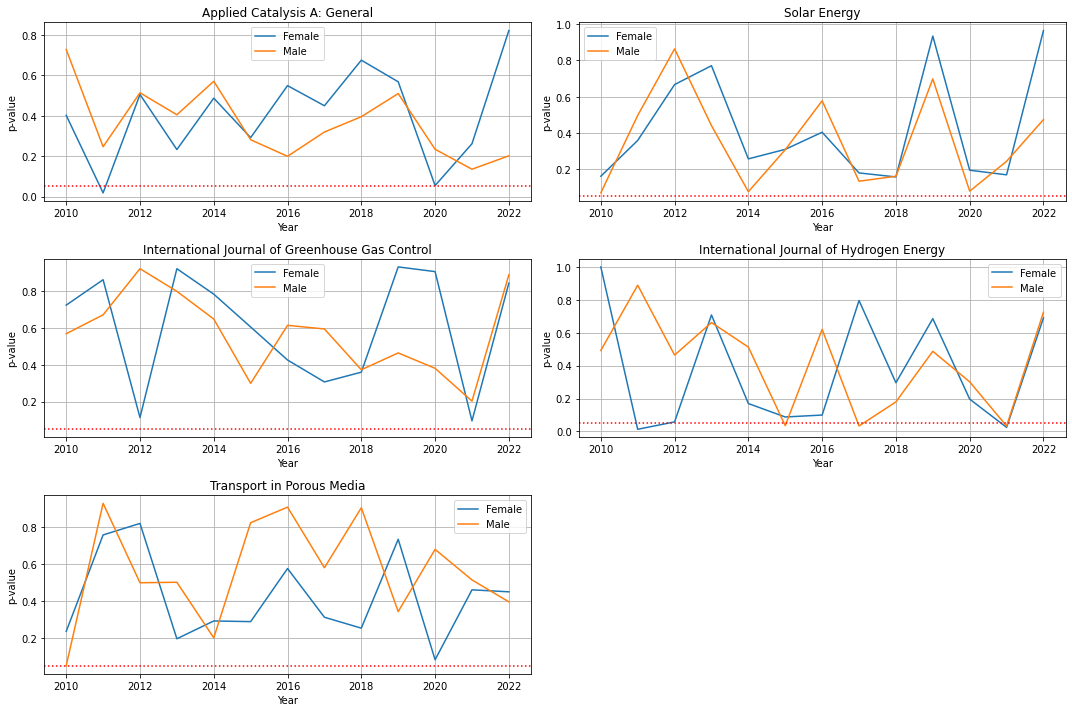

In [28]:
start_year = 2010
end_year = 2023
time_period = 1
alpha = 0.05

publication_titles = ["Applied Catalysis A: General", "Solar Energy", "International Journal of Greenhouse Gas Control",
                     "International Journal of Hydrogen Energy", "Transport in Porous Media"]

num_titles = len(publication_titles)
num_cols = 2
num_rows = (num_titles + num_cols - 1) // num_cols

fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(num_rows, num_cols, figure=fig)

for idx, title in enumerate(publication_titles):
    ax = fig.add_subplot(gs[idx // num_cols, idx % num_cols])
    ax.set_title(title)
    
    p_values_female, p_values_male = significance_and_correlation(start_year, end_year, time_period, data[data['Publication Title'] == title], alpha)
    
    ax.plot(range(start_year, end_year, time_period), p_values_female, label='Female')
    ax.plot(range(start_year, end_year, time_period), p_values_male, label='Male')
    
    ax.axhline(y=0.05, color='red', linestyle='dotted')
    
    ax.set_xlabel('Year')
    ax.set_ylabel('p-value')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.savefig('p-values-by-year.png')

Time Period: 2010 - 2010
Publication Title: Applied Catalysis A: General
p-value for females (Count_Female): 0.4493289641172217
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.44329635837453063
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2011 - 2011
Publication Title: Applied Catalysis A: General
p-value for females (Count_Female): 0.06005466789530797
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.30621891841327764
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count

C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))
C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))


p-value for females (Count_Female): 0.26146412994911117
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.26146412994911117
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): nan
Cramer's V correlation coefficient (using Count_Male): nan


Time Period: 2014 - 2014
Publication Title: Solar Energy
p-value for females (Count_Female): 0.14895400671141998
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.2172995701784638
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.53
Cramer's V correlation coefficient (using Count_Male): 0.38


Time Period: 2

C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))
C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))
C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))
C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/3879203197.py:12: RuntimeWarning: invalid value encountered in scalar divide
  statistic = np.sqrt(phi2_corrected / min(r_corrected - 1, k_corrected - 1))


Cramer's V correlation coefficient (using Count_Female): 0.45
Cramer's V correlation coefficient (using Count_Male): 0.27


Time Period: 2019 - 2019
Publication Title: Solar Energy
p-value for females (Count_Female): 0.6328289771977345
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.6995152511180547
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2020 - 2020
Publication Title: Solar Energy
p-value for females (Count_Female): 0.34106217837327013
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.2311428946734249
There is no significant correlation between first_author_gender and the c

Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2011 - 2011
Publication Title: International Journal of Hydrogen Energy
p-value for females (Count_Female): 0.11327770903101163
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.9947542015820027
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.33
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2012 - 2012
Publication Title: International Journal of Hydrogen Energy
p-value for females (Count_Female): 0.2031698313998986
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.3368416030583411
There is no signi

p-value for males (Count_Male): 0.5730246537103134
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2014 - 2014
Publication Title: Transport in Porous Media
p-value for females (Count_Female): 1.0
There is no significant correlation between first_author_gender and the count of females in the authors_genders list.
p-value for males (Count_Male): 0.39160562667679893
There is no significant correlation between first_author_gender and the count of males in the authors_genders list.
Cramer's V correlation coefficient (using Count_Female): 0.00
Cramer's V correlation coefficient (using Count_Male): 0.00


Time Period: 2015 - 2015
Publication Title: Transport in Porous Media
p-value for females (Count_Female): 0.16754627748861323
There is no significant correlation between first_author_gender

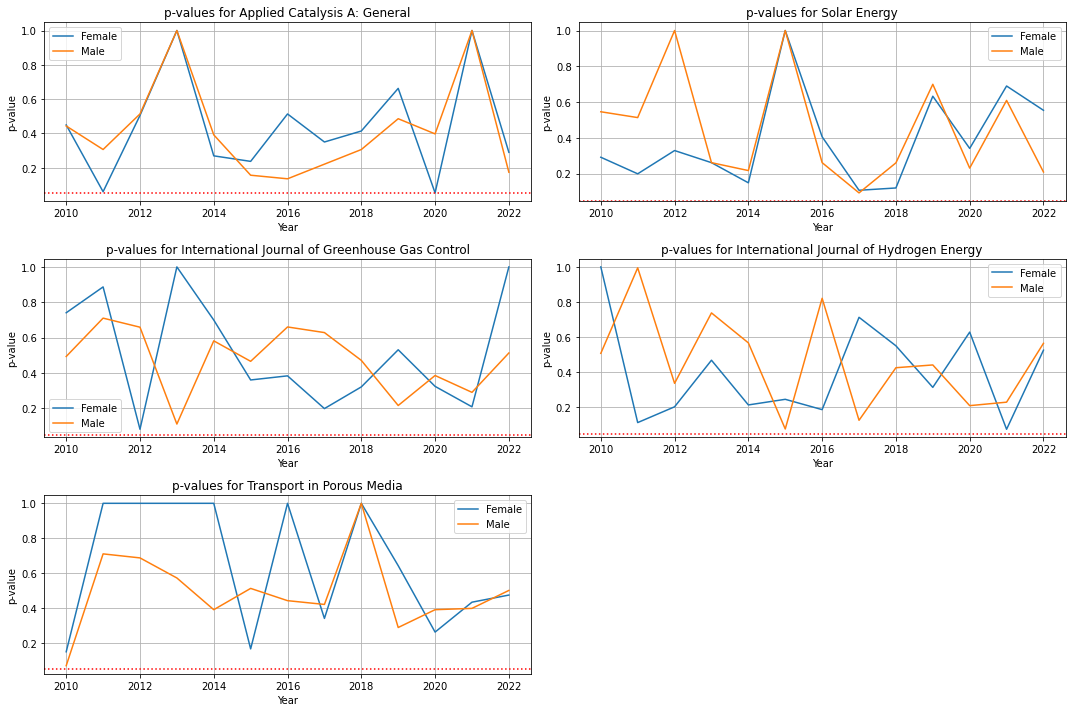

In [29]:
num_rows = 2
num_cols = 3
total_plots = num_rows * num_cols

publication_titles = ["Applied Catalysis A: General", "Solar Energy", "International Journal of Greenhouse Gas Control",
                     "International Journal of Hydrogen Energy", "Transport in Porous Media"]

p_values_dict_female = {}
p_values_dict_male = {}

for title in publication_titles:
    title_data = data[data['Publication Title'] == title]
    
    min_sample_size = min(len(title_data[title_data['first_author_gender'] == 'male']),
                          len(title_data[title_data['first_author_gender'] == 'female']))
    
    male_subset = title_data[title_data['first_author_gender'] == 'male'].sample(n=min_sample_size, random_state=42)
    
    balanced_data = pd.concat([title_data[title_data['first_author_gender'] == 'female'], male_subset], axis=0)
    
    p_values_female, p_values_male = significance_and_correlation(start_year, end_year, time_period, balanced_data, alpha, title)
    
    p_values_dict_female[title] = p_values_female
    p_values_dict_male[title] = p_values_male

num_titles = len(publication_titles)
num_cols = 2
num_rows = (num_titles + num_cols - 1) // num_cols

fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(num_rows, num_cols, figure=fig)

for idx, title in enumerate(publication_titles):
    row = idx // num_cols
    col = idx % num_cols
    
    ax = fig.add_subplot(gs[idx // num_cols, idx % num_cols])
    ax.plot(range(start_year, end_year, time_period), p_values_dict_female[title], label='Female')
    ax.plot(range(start_year, end_year, time_period), p_values_dict_male[title], label='Male')
    ax.set_xlabel('Year')
    ax.set_ylabel('p-value')
    ax.set_title(f'p-values for {title}')
    ax.legend()
    ax.grid()
    ax.axhline(y=0.05, color='red', linestyle='dotted')

gs.tight_layout(fig)
plt.show('balanced-p-values-by-year.png')

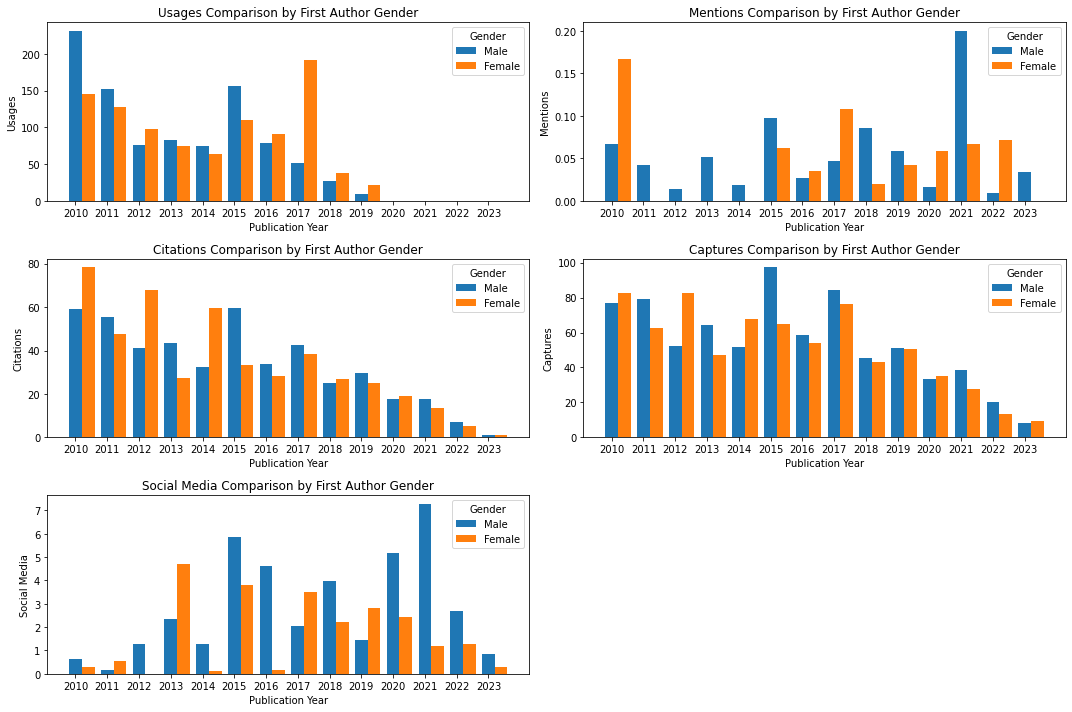

In [30]:
df = data

df = data[(data['Publication Year'] >= 2010) & (data['Publication Year'] <= 2023)]

metrics = ['Usages', 'Mentions', 'Citations', 'Captures', 'Social Media']

fig = plt.figure(figsize=(15, 10))
grid = gridspec.GridSpec(3, 2, figure=fig)

for idx, metric in enumerate(metrics):
    pivot_df = df.pivot_table(index='Publication Year', columns='first_author_gender', values=metric, aggfunc='mean')
    
    years = pivot_df.index
    male_values = pivot_df['male']
    female_values = pivot_df['female']
    
    row = idx // 2
    col = idx % 2
    
    ax = fig.add_subplot(grid[row, col])
    
    ax.bar(years, male_values, width=0.4, label='Male', align='edge')
    ax.bar(years + 0.4, female_values, width=0.4, label='Female', align='edge')
    
    ax.set_xlabel('Publication Year')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} Comparison by First Author Gender')
    ax.legend(title='Gender')
    ax.set_xticks(years + 0.2)
    ax.set_xticklabels(years)
    
plt.tight_layout()
plt.savefig('normalised-impact-metrics.png')

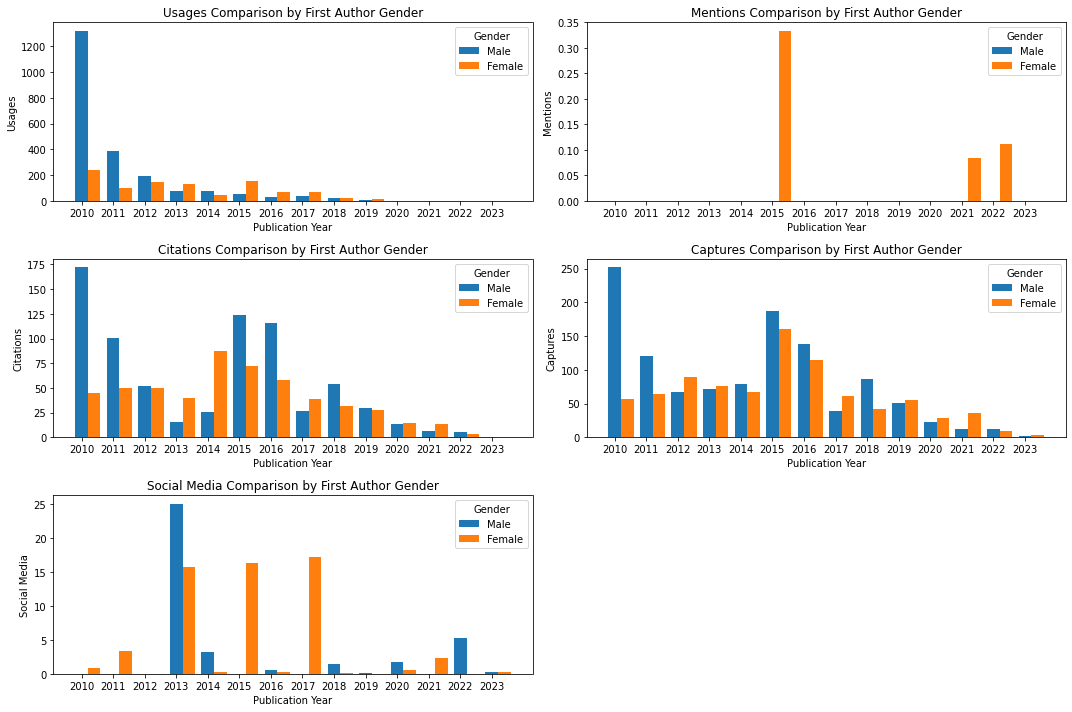

In [31]:
df = data[data['ratio_female_authors'] >= 0.75]

df = df[(df['Publication Year'] >= 2010) & (df['Publication Year'] <= 2023)]

metrics = ['Usages', 'Mentions', 'Citations', 'Captures', 'Social Media']

fig = plt.figure(figsize=(15, 10))
grid = gridspec.GridSpec(3, 2, figure=fig)

for idx, metric in enumerate(metrics):
    pivot_df = df.pivot_table(index='Publication Year', columns='first_author_gender', values=metric, aggfunc='mean')
    
    years = pivot_df.index
    male_values = pivot_df['male']
    female_values = pivot_df['female']
    
    row = idx // 2
    col = idx % 2
    
    ax = fig.add_subplot(grid[row, col])
    
    ax.bar(years, male_values, width=0.4, label='Male', align='edge')
    ax.bar(years + 0.4, female_values, width=0.4, label='Female', align='edge')
    
    ax.set_xlabel('Publication Year')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} Comparison by First Author Gender')
    ax.legend(title='Gender')
    ax.set_xticks(years + 0.2)
    ax.set_xticklabels(years)
    
plt.tight_layout()
plt.savefig('threshold-75-impact-metrics.png')

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm

df = data[(data['Publication Year'] >= 2010) & (data['Publication Year'] <= 2023)]
df['first_author_gender'] = df['first_author_gender'].map({'male': 0, 'female': 1})

df['Authors H-index'].fillna(0, inplace=True)

dependent_variable = 'first_author_gender'
independent_variables = ['Citations', 'Usages', 'Mentions', 'Social Media', 'Captures']

train_data, test_data = train_test_split(df, test_size=0.2, random_state=42)

X_train = sm.add_constant(train_data[independent_variables])
X_test = sm.add_constant(test_data[independent_variables])

logit_model = sm.Logit(train_data[dependent_variable], X_train)
results = logit_model.fit()

predicted_probs = results.predict(X_test)

predicted_classes = (predicted_probs > 0.5).astype(int)

accuracy = accuracy_score(test_data[dependent_variable], predicted_classes)
precision = precision_score(test_data[dependent_variable], predicted_classes,zero_division=1)
recall = recall_score(test_data[dependent_variable], predicted_classes,zero_division=1)
f1 = f1_score(test_data[dependent_variable], predicted_classes,zero_division=1)
mse = mean_squared_error(test_data[dependent_variable], predicted_probs)
mae = mean_absolute_error(test_data[dependent_variable], predicted_probs)
r2 = r2_score(test_data[dependent_variable], predicted_probs)

print(results.summary())
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"R-squared: {r2:.2f}")
print("="*50)

C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/1044472970.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['first_author_gender'] = df['first_author_gender'].map({'male': 0, 'female': 1})
C:\Users\aznur\AppData\Local\Temp/ipykernel_23832/1044472970.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Authors H-index'].fillna(0, inplace=True)


NameError: name 'train_test_split' is not defined

In [ ]:
def process_h_index_value(val):
    if isinstance(val, str):
        values = [int(v) for v in val.split(', ') if v.isdigit()]
        return np.mean(values)
    elif isinstance(val, (int, float)):
        return val
    else:
        return int(0)

data['Authors H-index'] = data['Authors H-index'].apply(process_h_index_value)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LogisticRegression

df = data[(data['Publication Year'] >= 2010) & (data['Publication Year'] <= 2023)]
df['first_author_gender'] = df['first_author_gender'].map({'male': 0, 'female': 1})

publication_titles = df['Publication Title'].unique()

df['Authors H-index'].fillna(0, inplace=True)

for title in publication_titles:
    title_data = df[df['Publication Title'] == title]
    
    dependent_variable = 'first_author_gender'
    independent_variables = ['Citations', 'Usages', 'Mentions', 'Social Media', 'Captures',
                            'Publication Year', 'First Author H-Index', 'Authors H-index',
                            'num_female_authors', 'num_male_authors', 'num_authors', 
                             'First Author Affiliation ID']
    
    train_data, test_data = train_test_split(title_data, test_size=0.2, random_state=42)
    
    X_train = sm.add_constant(train_data[independent_variables])
    X_test = sm.add_constant(test_data[independent_variables])
    
    logit_model = sm.Logit(train_data[dependent_variable], X_train)
    
    results = logit_model.fit()
    
    predicted_probs = results.predict(X_test)
    
    predicted_classes = (predicted_probs > 0.5).astype(int)
    
    accuracy = accuracy_score(test_data[dependent_variable], predicted_classes)
    precision = precision_score(test_data[dependent_variable], predicted_classes,zero_division=1)
    recall = recall_score(test_data[dependent_variable], predicted_classes,zero_division=1)
    f1 = f1_score(test_data[dependent_variable], predicted_classes,zero_division=1)
    mse = mean_squared_error(test_data[dependent_variable], predicted_probs)
    mae = mean_absolute_error(test_data[dependent_variable], predicted_probs)
    r2 = r2_score(test_data[dependent_variable], predicted_probs)
    
    print(f"Publication Title: {title}")
    print(results.summary())
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-Score: {f1:.2f}")
    print(f"Mean Squared Error: {mse:.2f}")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"R-squared: {r2:.2f}")
    print("="*50)

    lasso_model = LogisticRegression(penalty='l1', solver='liblinear')
    ridge_model = LogisticRegression(penalty='l2')

    model_l = lasso_model.fit(X_train, train_data[dependent_variable])
    model_r = ridge_model.fit(X_train, train_data[dependent_variable])
    
    predicted_lasso = model_l.predict(X_test)
    predicted_ridge = model_r.predict(X_test)
    
    predicted_l = (predicted_lasso > 0.5).astype(int)
    predicted_r = (predicted_ridge > 0.5).astype(int)

    accuracy_l = accuracy_score(test_data[dependent_variable], predicted_l)
    precision_l = precision_score(test_data[dependent_variable], predicted_l, zero_division=1)
    recall_l = recall_score(test_data[dependent_variable], predicted_l, zero_division=1)
    f1_l = f1_score(test_data[dependent_variable], predicted_l, zero_division=1)
    mse_l = mean_squared_error(test_data[dependent_variable], predicted_lasso)
    mae_l = mean_absolute_error(test_data[dependent_variable], predicted_lasso)
    r2_l = r2_score(test_data[dependent_variable], predicted_lasso)
    
    accuracy_r = accuracy_score(test_data[dependent_variable], predicted_r)
    precision_r = precision_score(test_data[dependent_variable], predicted_r, zero_division=1)
    recall_r = recall_score(test_data[dependent_variable], predicted_r, zero_division=1)
    f1_r = f1_score(test_data[dependent_variable], predicted_r, zero_division=1)
    mse_r = mean_squared_error(test_data[dependent_variable], predicted_ridge)
    mae_r = mean_absolute_error(test_data[dependent_variable], predicted_ridge)
    r2_r = r2_score(test_data[dependent_variable], predicted_ridge)
    
    print("Lasso Regularization:")
    print(f"Accuracy: {accuracy_l:.2f}")
    print(f"Precision: {precision_l:.2f}")
    print(f"Recall: {recall_l:.2f}")
    print(f"F1-Score: {f1_l:.2f}")
    print(f"Mean Squared Error: {mse_l:.2f}")
    print(f"Mean Absolute Error: {mae_l:.2f}")
    print(f"R-squared: {r2_l:.2f}")
    print("="*50)
    
    print("Ridge Regularization:")
    print(f"Accuracy: {accuracy_r:.2f}")
    print(f"Precision: {precision_r:.2f}")
    print(f"Recall: {recall_r:.2f}")
    print(f"F1-Score: {f1_r:.2f}")
    print(f"Mean Squared Error: {mse_r:.2f}")
    print(f"Mean Absolute Error: {mae_r:.2f}")
    print(f"R-squared: {r2_r:.2f}")
    print("="*50)

In [ ]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

dependent_variable = 'Citations'
independent_variables = ['Usages', 'Mentions', 'Social Media', 'Captures',
                        'Publication Year', 'First Author H-Index', 'Authors H-index',
                        'num_authors', 'first_author_gender', 'First Author Affiliation ID']

for title in publication_titles:
    title_data = df[df['Publication Title'] == title]
    
    train_data, test_data = train_test_split(title_data, test_size=0.2, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(train_data[independent_variables])
    X_test_scaled = scaler.transform(test_data[independent_variables])
    
    svr_model = SVR(kernel='linear')
    
    svr_model.fit(X_train_scaled, train_data[dependent_variable])
    
    predicted_citations = svr_model.predict(X_test_scaled)
    
    mse = mean_squared_error(test_data[dependent_variable], predicted_citations)
    mae = mean_absolute_error(test_data[dependent_variable], predicted_citations)
    r2 = r2_score(test_data[dependent_variable], predicted_citations)
    
    print(f"Publication Title: {title}")
    print(f"Mean Squared Error: {mse:.2f}")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"R-squared: {r2:.2f}")
    print("="*50)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dependent_variable = 'first_author_gender'
independent_variables = ['Citations', 'Usages', 'Mentions', 'Social Media', 'Captures',
                        'Publication Year', 'First Author H-Index', 'Authors H-index',
                        'num_authors']

X = df[independent_variables]
y = df[dependent_variable]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

rf_classifier.fit(X_train, y_train)

predictions = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print("Random Forest Accuracy:", accuracy)

conf_matrix = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", conf_matrix)

class_report = classification_report(y_test, predictions)
print("Classification Report:\n", class_report)

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df[independent_variables]
y = df[dependent_variable]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_classifier = SVC(kernel='linear', C=1.0, random_state=42)

svm_classifier.fit(X_train_scaled, y_train)

predictions = svm_classifier.predict(X_test_scaled)

accuracy = accuracy_score(y_test, predictions)
print("SVM Accuracy:", accuracy)

conf_matrix = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", conf_matrix)

class_report = classification_report(y_test, predictions)
print("Classification Report:\n", class_report)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df[independent_variables]
y = df[dependent_variable]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_classifier = KNeighborsClassifier(n_neighbors=5)

knn_classifier.fit(X_train_scaled, y_train)

predictions = knn_classifier.predict(X_test_scaled)

accuracy = accuracy_score(y_test, predictions)
print("K-Nearest Neighbors Accuracy:", accuracy)

conf_matrix = confusion_matrix(y_test, predictions)
print("Confusion Matrix:\n", conf_matrix)

class_report = classification_report(y_test, predictions)
print("Classification Report:\n", class_report)